In [48]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.neighbors import KNeighborsClassifier
import itertools
import pandas as pd

In [2]:
np.random.seed(42)

In [3]:
SQUARE_SIZE = 10.0
TRIANGLE_VERTICES = np.array([[3.0, 3.0], [7.0, 3.0], [7.0, 7.0]])

def point_in_triangle(points, vertices=TRIANGLE_VERTICES):
    vertex_a, vertex_b, vertex_c = vertices

    def cross_product(origin, point_one, point_two):
        return (point_one[0] - origin[0]) * (point_two[1] - origin[1]) - (point_one[1] - origin[1]) * (point_two[0] - origin[0])

    tPoints = np.transpose(points)
    side_ab = cross_product(vertex_a, vertex_b, tPoints)
    side_bc = cross_product(vertex_b, vertex_c, tPoints)
    side_ca = cross_product(vertex_c, vertex_a, tPoints)
    has_negative_side = (side_ab < 0) | (side_bc < 0) | (side_ca < 0)
    has_positive_side = (side_ab > 0) | (side_bc > 0) | (side_ca > 0)
    return ~(has_negative_side & has_positive_side)

In [4]:
DEFAULT_NEIGHBOR_COUNT = 7
DEFAULT_POINT_COUNT = 1000
DEFAULT_OUTLIER_FRACTION = 0.0
TEST_POINT_COUNT = 10000
REPEAT_COUNT = 30

In [5]:
def perform_multiple_times(performer, paramSets):
    results = {}
    for params in paramSets:
        totalMisclassifications = 0
        for _ in range(REPEAT_COUNT):
            sample = performer(params)
            pred = sample["pred"]
            truth = sample["truth"]
            misclassifications = np.count_nonzero(pred != truth)
            totalMisclassifications += misclassifications
        results[params] = totalMisclassifications / REPEAT_COUNT
    return results

In [6]:
def flat_rate_outliers(fraction):
    def outlier_generator(X):
        return np.random.rand(X.shape[0]) < fraction
    return outlier_generator

In [7]:
def uniform_point_generator(size):
    return np.random.rand(size, 2) * SQUARE_SIZE

In [8]:

def perform_experiment(generator, trainSize, outlierGenerator, neighborCount, testGenerator=None):
    X_train = generator(trainSize)
    outlierMask = outlierGenerator(X_train)
    y_train = np.logical_xor(point_in_triangle(X_train), outlierMask)

    knn = KNeighborsClassifier(n_neighbors=neighborCount)
    knn.fit(X_train, y_train)

    X_test = (testGenerator or generator)(TEST_POINT_COUNT)
    y_test = point_in_triangle(X_test)

    pred = knn.predict(X_test)
    return {"pred": pred, "truth": y_test}

In [9]:
def visualize_training_set(X_train, y_train, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(5, 5))

    insideMask = y_train.astype(bool)
    
    # Plot points: red outside, blue inside
    ax.scatter(
        X_train[~insideMask, 0], X_train[~insideMask, 1],
        c="red", s=20, linewidths=0, zorder=3
    )
    ax.scatter(
        X_train[insideMask, 0], X_train[insideMask, 1],
        c="blue", s=20, linewidths=0, zorder=3
    )

    # Draw square boundary
    square = plt.Rectangle(
        (0.0, 0.0), SQUARE_SIZE, SQUARE_SIZE,
        fill=False, edgecolor="black", linewidth=1.5, zorder=2
    )
    ax.add_patch(square)

    # Draw triangle boundary
    closedTriangle = np.vstack([TRIANGLE_VERTICES, TRIANGLE_VERTICES[0]])
    ax.plot(
        closedTriangle[:, 0], closedTriangle[:, 1],
        color="black", linewidth=1.5, zorder=2
    )

    # Set limits slightly outside to make room for the text annotations
    ax.set_xlim(-0.5, SQUARE_SIZE + 0.5)
    ax.set_ylim(-0.5, SQUARE_SIZE + 0.5)
    ax.set_aspect("equal")

    # Remove axes ticks and spines
    ax.set_xticks([])
    ax.set_yticks([])
    for spine in ax.spines.values():
        spine.set_visible(False)

    # Add corner annotations
    ax.text(-0.2, -0.2, "(0, 0)", fontsize=14, ha="right", va="top")
    ax.text(SQUARE_SIZE + 0.2, SQUARE_SIZE + 0.2, "(10, 10)", fontsize=14, ha="left", va="bottom")

    return ax


def visualize_generated_training_set(generator, trainSize, outlierGenerator, ax=None):
    X_train = generator(trainSize)
    outlierMask = outlierGenerator(X_train)
    y_train = np.logical_xor(point_in_triangle(X_train), outlierMask)
    return visualize_training_set(X_train, y_train, ax=ax)

# Actual experiments

## Variable density (E. 1)

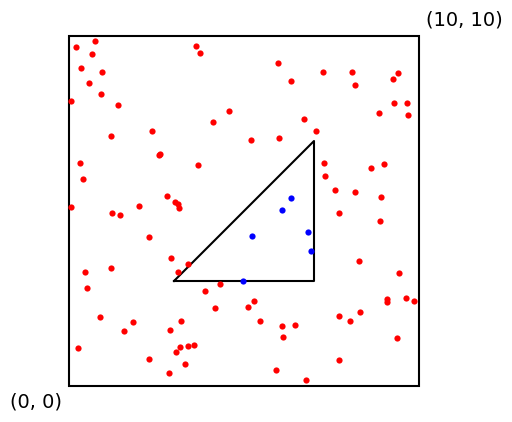

Dataset 100 accurately labeled points (n = 100, k = 7, f = 0.0, bias = 0.0)


In [10]:
visualize_generated_training_set(
    uniform_point_generator,
    trainSize=100,
    outlierGenerator=flat_rate_outliers(DEFAULT_OUTLIER_FRACTION)
)
plt.show()
print(f"Dataset 100 accurately labeled points (n = 100, k = {DEFAULT_NEIGHBOR_COUNT}, f = {DEFAULT_OUTLIER_FRACTION}, bias = 0.0)")

In [11]:
data = perform_multiple_times(
    lambda n: perform_experiment(
        uniform_point_generator,
        n,
        flat_rate_outliers(DEFAULT_OUTLIER_FRACTION),
        DEFAULT_NEIGHBOR_COUNT
    ),
    [100, 200, 300, 400, 500, 600, 700, 800, 900, 1000])

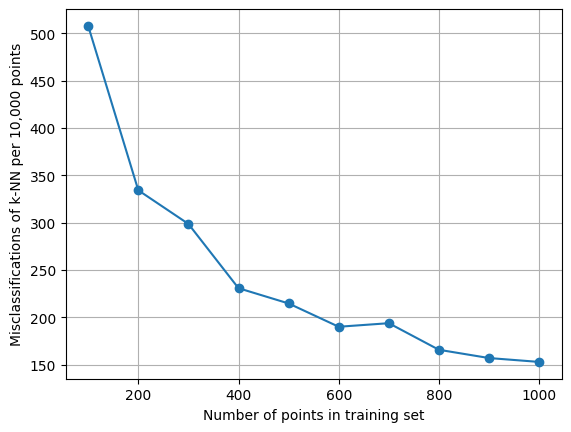

In [12]:
x, y = data.keys(), data.values()

plt.plot(x, y, marker="o")
plt.xlabel("Number of points in training set")
plt.ylabel("Misclassifications of k-NN per 10,000 points")
plt.grid(True)
plt.show()

## Variable outlier fraction (E. 2)

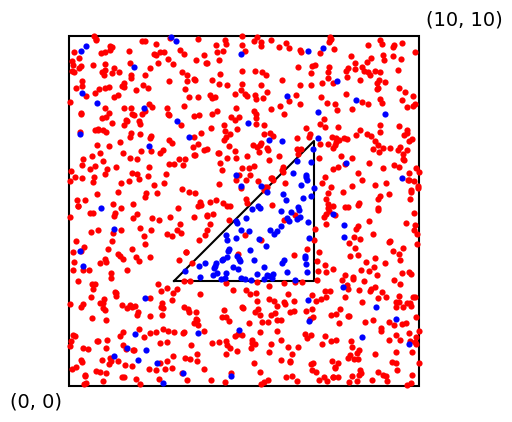

Dataset with 5.0% outliers (n = 1000, k = 7, f = 0.05, bias = 0.0)


In [13]:
visualize_generated_training_set(
    uniform_point_generator,
    trainSize=DEFAULT_POINT_COUNT,
    outlierGenerator=flat_rate_outliers(0.05)
)
plt.show()
print(f"Dataset with {0.05 * 100}% outliers (n = {DEFAULT_POINT_COUNT}, k = {DEFAULT_NEIGHBOR_COUNT}, f = {0.05}, bias = 0.0)")

In [14]:
data = perform_multiple_times(
    lambda f: perform_experiment(
        uniform_point_generator,
        DEFAULT_POINT_COUNT,
        flat_rate_outliers(f),
        DEFAULT_NEIGHBOR_COUNT
    ),
    [0.0, 0.05, 0.1, 0.15, 0.2, 0.25, 0.3])

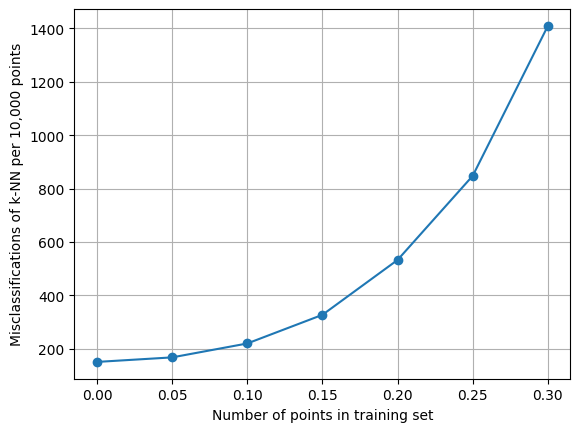

In [15]:
x, y = data.keys(), data.values()

plt.plot(x, y, marker="o")
plt.xlabel("Number of points in training set")
plt.ylabel("Misclassifications of k-NN per 10,000 points")
plt.grid(True)
plt.show()

## Uniform variable relative densities (E. 3.1)

In [16]:
def biased_uniform_point_generator(bias=0.5):
    vertexA, vertexB, vertexC = TRIANGLE_VERTICES
    edgeAB = vertexB - vertexA
    edgeAC = vertexC - vertexA
    triangleArea = 0.5 * np.abs(edgeAB[0] * edgeAC[1] - edgeAB[1] * edgeAC[0])
    squareArea = SQUARE_SIZE * SQUARE_SIZE - triangleArea

    # bias * insideCount / triangleArea = (1 - bias) * outsideCount / squareArea
    # bias * insideFraction / triangleArea = (1 - bias) * outsideFraction / squareArea
    # bias * insideFraction / triangleArea = (1 - bias) * (1 - insideFraction) / squareArea

    insideFraction = (
        (1 - bias) * triangleArea
    ) / (
        bias * squareArea + (1 - bias) * triangleArea
    )

    def generator(size):
        insideCount = int(size * insideFraction)
        outsideCount = size - insideCount

        barycentricU = np.random.rand(insideCount)
        barycentricV = np.random.rand(insideCount)
        needsFold = barycentricU + barycentricV > 1
        barycentricU[needsFold] = 1 - barycentricU[needsFold]
        barycentricV[needsFold] = 1 - barycentricV[needsFold]
        insidePoints = (
            vertexA
            + barycentricU[:, None] * (vertexB - vertexA)
            + barycentricV[:, None] * (vertexC - vertexA)
        )

        outsidePoints = np.empty((0, 2))
        while len(outsidePoints) < outsideCount:
            remaining = outsideCount - len(outsidePoints)
            candidateCount = max(remaining * 2, 16)
            candidates = np.random.rand(candidateCount, 2) * SQUARE_SIZE
            outsidePoints = np.concatenate(
                [outsidePoints, candidates[~point_in_triangle(candidates)]]
            )
        outsidePoints = outsidePoints[:outsideCount]

        return np.concatenate([insidePoints, outsidePoints], axis=0)

    return generator

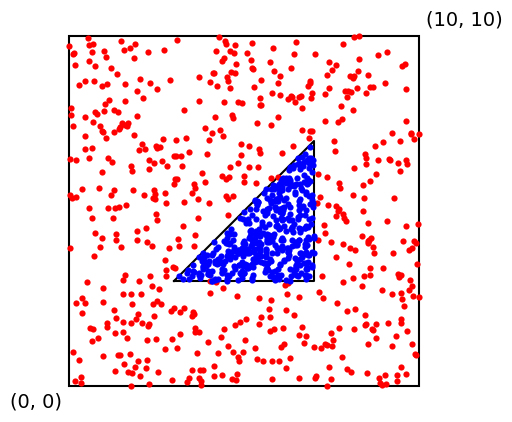

Biased relative density point generation (n = 1000, k = 7, f = 0.0, bias = 0.1)


In [17]:
visualize_generated_training_set(
    biased_uniform_point_generator(bias=0.1),
    trainSize=DEFAULT_POINT_COUNT,
    outlierGenerator=flat_rate_outliers(DEFAULT_OUTLIER_FRACTION)
)
plt.show()
print(f"Biased relative density point generation (n = {DEFAULT_POINT_COUNT}, k = {DEFAULT_NEIGHBOR_COUNT}, f = {DEFAULT_OUTLIER_FRACTION}, bias = 0.1)")

In [18]:
data = perform_multiple_times(
    lambda bias: perform_experiment(
        biased_uniform_point_generator(bias),
        DEFAULT_POINT_COUNT,
        flat_rate_outliers(DEFAULT_OUTLIER_FRACTION),
        DEFAULT_NEIGHBOR_COUNT
    ),
    [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

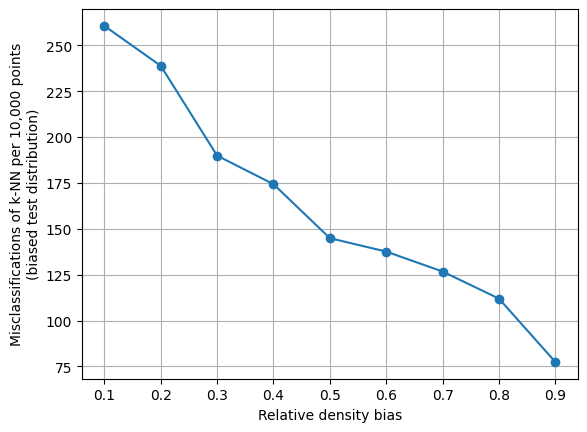

In [19]:
x, y = data.keys(), data.values()

plt.plot(x, y, marker="o")
plt.xlabel("Relative density bias")
plt.ylabel("Misclassifications of k-NN per 10,000 points\n(biased test distribution)")
plt.grid(True)
plt.show()

In [20]:
data = perform_multiple_times(
    lambda bias: perform_experiment(
        biased_uniform_point_generator(bias),
        DEFAULT_POINT_COUNT,
        flat_rate_outliers(DEFAULT_OUTLIER_FRACTION),
        DEFAULT_NEIGHBOR_COUNT,
        uniform_point_generator
    ),
    [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])

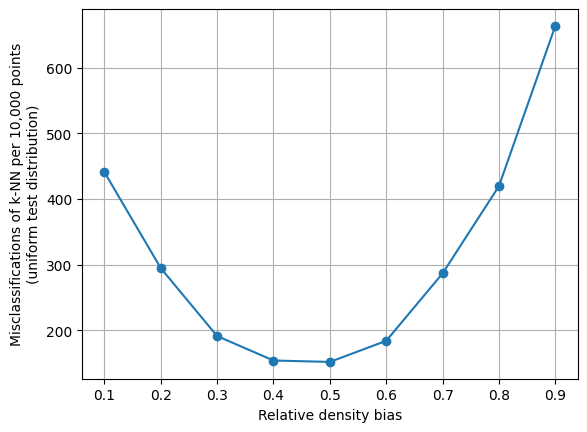

In [21]:
x, y = data.keys(), data.values()

plt.plot(x, y, marker="o")
plt.xlabel("Relative density bias")
plt.ylabel("Misclassifications of k-NN per 10,000 points\n(uniform test distribution)")
plt.grid(True)
plt.show()

## Gaussian variable relative densities (E. 3.2)

In [41]:
DEFAULT_STDDEV = 1.5

In [42]:
def gaussian_point_generator(origin=(5.0, 5.0), stddev=DEFAULT_STDDEV):
    def generator(size):
        return np.random.normal(origin, stddev, (size, 2))

    return generator

In [50]:
def distribution_to_bias(origin, stddev = DEFAULT_STDDEV):
    vertexA, vertexB, vertexC = TRIANGLE_VERTICES
    edgeAB = vertexB - vertexA
    edgeAC = vertexC - vertexA
    triangleArea = 0.5 * np.abs(edgeAB[0] * edgeAC[1] - edgeAB[1] * edgeAC[0])
    squareArea = SQUARE_SIZE * SQUARE_SIZE - triangleArea

    count = 10000
    points = gaussian_point_generator(origin, stddev)(count)
    insideMask = point_in_triangle(points)
    insideCount = np.count_nonzero(insideMask)
    insideFraction = insideCount / count
    return (
        (1 - insideFraction) * triangleArea
    ) / (
        insideFraction * squareArea + (1 - insideFraction) * triangleArea
    )

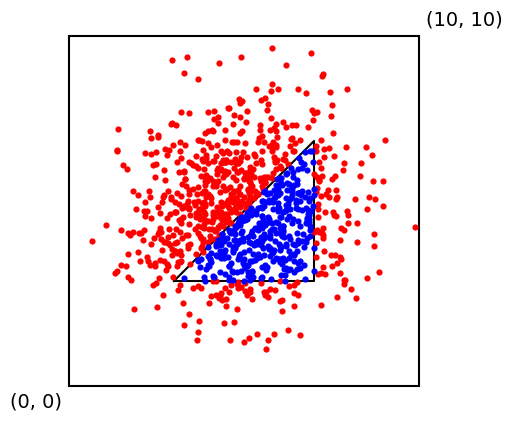

Biased relative density point generation(n = 1000, k = 7, f = 0.0, center = (5, 5), approx. bias = 0.14398042984448714)


In [44]:
visualize_generated_training_set(
    gaussian_point_generator(origin=(5.0, 5.0), stddev=DEFAULT_STDDEV),
    trainSize=DEFAULT_POINT_COUNT,
    outlierGenerator=flat_rate_outliers(DEFAULT_OUTLIER_FRACTION)
)
plt.show()
print("Biased relative density point generation" +
      f"(n = {DEFAULT_POINT_COUNT}, k = {DEFAULT_NEIGHBOR_COUNT}, f = {DEFAULT_OUTLIER_FRACTION}, center = (5, 5), approx. bias = {distribution_to_bias((5.0, 5.0), 1.5)})")

In [62]:
origins = list(itertools.product(np.linspace(0, 10, 5), np.linspace(0, 10, 5)))
biases = {origin: distribution_to_bias(origin) for origin in origins}

In [65]:
data = perform_multiple_times(
    lambda origin: perform_experiment(
        gaussian_point_generator(origin=origin),
        DEFAULT_POINT_COUNT,
        flat_rate_outliers(DEFAULT_OUTLIER_FRACTION),
        DEFAULT_NEIGHBOR_COUNT
    ),
    origins)

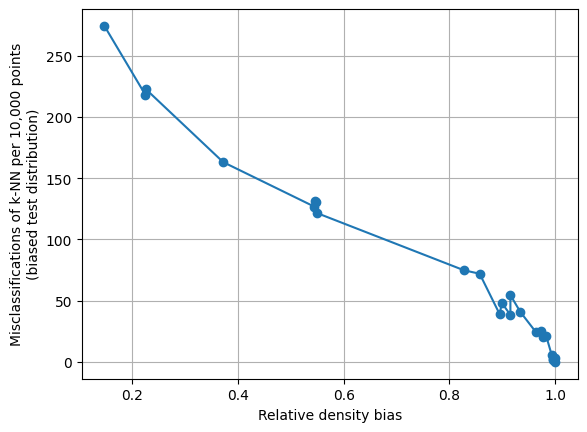

In [66]:
pairs = sorted(
    ((biases[origin], misclassifications) for origin, misclassifications in data.items()),
    key=lambda pair: pair[0],
)
x, y = zip(*pairs)

plt.plot(x, y, marker="o")
plt.xlabel("Relative density bias")
plt.ylabel("Misclassifications of k-NN per 10,000 points\n(biased test distribution)")
plt.grid(True)
plt.show()

In [67]:
data = perform_multiple_times(
    lambda origin: perform_experiment(
        gaussian_point_generator(origin=origin),
        DEFAULT_POINT_COUNT,
        flat_rate_outliers(DEFAULT_OUTLIER_FRACTION),
        DEFAULT_NEIGHBOR_COUNT,
        uniform_point_generator
    ),
    origins)

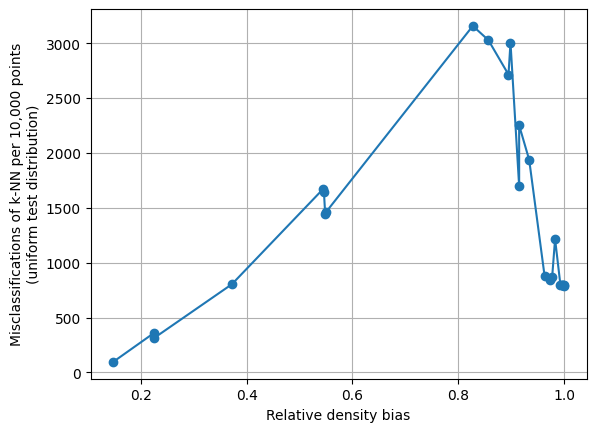

In [68]:
pairs = sorted(
    ((biases[origin], misclassifications) for origin, misclassifications in data.items()),
    key=lambda pair: pair[0],
)
x, y = zip(*pairs)

plt.plot(x, y, marker="o")
plt.xlabel("Relative density bias")
plt.ylabel("Misclassifications of k-NN per 10,000 points\n(uniform test distribution)")
plt.grid(True)
plt.show()